# 3_model — Türkiye Saatlik Tüketim Tahmini: Baseline, XGBoost, LSTM ve Resmî Plan Kıyası

- **A.** Kurulum, veri ve zaman bazlı ayrım
- **B.** HDD/CDD bazlarının yalnızca eğitim döneminden yeniden seçilmesi
- **C.** Özellik setleri ve metrikler
- **D.** Ortak test kümesi, baseline'lar ve resmî yük planı
- **E.** XGBoost — 1 saat ileri
- **F.** XGBoost — gün öncesi (iki sıcaklık varsayımıyla)
- **G.** LSTM — 1 saat ileri
- **H.** Karşılaştırma, hata analizi ve kayıt

**İki görev neden ayrı:**
- **1 saat ileri tahmin**, bir saat önceki gerçek tüketimi (`lag_1`) kullanabilir; PJM projesiyle karşılaştırılabilir.
- **Resmî Yük Tahmin Planı** ise ertesi gün için yapılan bir tahmin. Onunla adil bir kıyas için modelimiz de **gün öncesi** koşullarda çalışmalı: yalnızca en az 48 saat önceki tüketim bilgisi.

**Girdiler:** `data/tr_ozellikli_saatlik.csv`, `data/tr_yuk_plani_saatlik.csv`, `metrics/ozellik_ayarlari.json` (`2_ozellik.ipynb` çıktıları)

## A. Kurulum ve Veri

### A1. Veri ve ayarlar

In [16]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import xgboost as xgb

KOK = r"C:\Deep_Learning_to_AI_Agents\Bitirme_Proje_Bonus"
os.makedirs(os.path.join(KOK, "agent"), exist_ok=True)
np.random.seed(42)

df = pd.read_csv(os.path.join(KOK, "data", "tr_ozellikli_saatlik.csv"))
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

lp = pd.read_csv(os.path.join(KOK, "data", "tr_yuk_plani_saatlik.csv"))
lp["date"] = pd.to_datetime(lp["date"])
df = df.merge(lp[["date", "lep"]], on="date", how="left")

with open(os.path.join(KOK, "metrics", "ozellik_ayarlari.json"), encoding="utf-8") as f:
    ayar = json.load(f)
print("Satir:", len(df), "| aralik:", df["date"].min(), "->", df["date"].max())
print("2_ozellik bazlari (tum donem): HDD", ayar["hdd_tabani_c"], "C, CDD", ayar["cdd_tabani_c"], "C")
print("Resmi planin eksik oldugu saat:", int(df["lep"].isna().sum()))

Satir: 91968 | aralik: 2016-04-01 00:00:00+03:00 -> 2026-09-27 23:00:00+03:00
2_ozellik bazlari (tum donem): HDD 13.5 C, CDD 17.0 C
Resmi planin eksik oldugu saat: 24


### A2. Zaman bazlı ayrım

| Bölüm | Dönem | Neden |
|---|---|---|
| Eğitim | 2016-04 → 2024-09 | Yaklaşık 8,5 yıl |
| Doğrulama | 2024-10 → 2025-09 | Tam bir yıl; erken durdurma için |
| Test | 2025-10 → 2026-09-22 | Tam bir yıla yakın; sıcaklık verisi 22 Eylül'de bittiği için orada bitiyor |

Doğrulama ve test dönemlerinin her biri bir yıla yakın; böylece her mevsim ve her bayram tipi içlerinde yer alıyor. Test dönemi, yeni EAK dönemine (Mart 2025 sonrası) düşüyor, yani Agent katmanının kullanacağı dönemle aynı.

In [17]:
EGITIM_BIT = pd.Timestamp("2024-10-01T00:00:00+03:00")
DOGRULAMA_BIT = pd.Timestamp("2025-10-01T00:00:00+03:00")
TEST_BIT = pd.Timestamp("2026-09-23T00:00:00+03:00")

df["bolum"] = np.select([df["date"] < EGITIM_BIT, df["date"] < DOGRULAMA_BIT, df["date"] < TEST_BIT],
                        ["egitim", "dogrulama", "test"], default="disarida")
print(df.groupby("bolum")["date"].agg(["min", "max", "count"]).to_string())

                                min                       max  count
bolum                                                               
disarida  2026-09-23 00:00:00+03:00 2026-09-27 23:00:00+03:00    120
dogrulama 2024-10-01 00:00:00+03:00 2025-09-30 23:00:00+03:00   8760
egitim    2016-04-01 00:00:00+03:00 2024-09-30 23:00:00+03:00  74520
test      2025-10-01 00:00:00+03:00 2026-09-22 23:00:00+03:00   8568


## B. HDD/CDD Bazlarının Eğitim Döneminden Yeniden Seçilmesi

`2_ozellik.ipynb` bazları tüm dönem üzerinde seçmişti; bu, test döneminin bilgisinin özellik tanımına sızması demek. Burada aynı yöntem (normal iş günleri, yıl etkili doğrusal model, R²) **yalnızca eğitim dönemiyle** tekrarlanıyor. Normal iş günü tanımı: hafta içi, tatil değil, idari izin değil, bayramın 3 gün çevresinde değil, sıcaklığı doldurulmamış.

In [18]:
egt = df[df["bolum"] == "egitim"].copy()
egt["gun_t"] = egt["date"].dt.tz_localize(None).dt.normalize()
g = egt.groupby("gun_t").agg(tuketim=("consumption", "sum"), n=("consumption", "size"), tavg=("tavg_c", "first"),
                              dol=("tavg_doldurma", "first"), tam=("tatil_tam", "max"), yarim=("tatil_yarim", "max"),
                              izin=("idari_izin", "max"), once=("bayram_once_gun", "first"),
                              sonra=("bayram_sonra_gun", "first"))
normal = g[(g.index.dayofweek < 5) & (g["n"] == 24) & (g["tam"] == 0) & (g["yarim"] == 0) & (g["izin"] == 0)
           & (g["once"] > 3) & (g["sonra"] > 3) & (g["dol"] == 0) & g["tavg"].notna()]
T, y = normal["tavg"].values, normal["tuketim"].values
yil_d = pd.get_dummies(normal.index.year, drop_first=True).values.astype(float)

def r2(h, c):
    X = np.column_stack([np.ones(len(y)), h, c, yil_d])
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    return 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum()

izgara = [(bh, bc, r2(np.maximum(0, bh - T), np.maximum(0, T - bc)))
          for bh in np.arange(10, 22.5, 0.5) for bc in np.arange(14, 26.5, 0.5) if bc >= bh]
izgara = pd.DataFrame(izgara, columns=["bh", "bc", "r2"]).sort_values("r2", ascending=False)
BH_TR, BC_TR = float(izgara.iloc[0]["bh"]), float(izgara.iloc[0]["bc"])
print("Egitim donemi normal is gunu:", len(normal))
print(izgara.head(5).round(4).to_string(index=False))
print(f"\nEgitim bazlari: HDD {BH_TR} C, CDD {BC_TR} C | tum donem bazlari: HDD {ayar['hdd_tabani_c']} C, CDD {ayar['cdd_tabani_c']} C")

df["hdd_tr"] = np.maximum(0, BH_TR - df["tavg_c"])
df["cdd_tr"] = np.maximum(0, df["tavg_c"] - BC_TR)

Egitim donemi normal is gunu: 2034
  bh   bc     r2
14.0 17.0 0.8133
13.5 17.0 0.8133
14.5 17.0 0.8131
13.0 17.0 0.8131
13.0 17.5 0.8130

Egitim bazlari: HDD 14.0 C, CDD 17.0 C | tum donem bazlari: HDD 13.5 C, CDD 17.0 C


## C. Özellik Setleri ve Metrikler

**Gün öncesi gecikmeler:** 48 ve 72 saat, 168 saat (geçen hafta aynı saat), ve 48 saat önce biten 24 ve 168 saatlik ortalamalar. 48 saatlik alt sınır ihtiyatlı bir seçim: tahmin ertesi günün bütün saatleri için bir önceki günün ortasında yapılıyormuş gibi davranıyor. Gerçek zamanlı tüketim de 2 saat gecikmeyle yayımlanıyor.

**Sıcaklık için iki varsayım (gün öncesi):**
- **Gerçekleşen sıcaklık:** Hedef günün gerçek sıcaklığı. Kusursuz bir hava tahminini varsayıyor; bu yüzden modele gerçekte sahip olmayacağı bir avantaj veriyor (literatürde "ex-post" değerlendirme).
- **Dünün sıcaklığı:** Hedef günden bir önceki günün gerçek sıcaklığı. Tahmin anında bilinen bir değer; ihtiyatlı alt sınır.

Resmî planın kendi hava tahminini kullandığı düşünülürse, adil kıyas bu ikisinin arasında bir yerde.

**Metrikler:**
- RMSPE: PJM projesindeki ana metrik.
- MAPE: Resmî planın %2,90'lık hatasıyla aynı metrik.
- MAE: MWh cinsinden.

In [19]:
df["lag_48"] = df["consumption"].shift(48)
df["lag_72"] = df["consumption"].shift(72)
df["rol_24_48"] = df["consumption"].shift(48).rolling(24).mean()
df["rol_168_48"] = df["consumption"].shift(48).rolling(168).mean()
df["tavg_dun"] = df["tavg_c"].shift(24)
df["hdd_dun"] = np.maximum(0, BH_TR - df["tavg_dun"])
df["cdd_dun"] = np.maximum(0, df["tavg_dun"] - BC_TR)

TAKVIM = ["saat", "gun", "ay", "hafta_sonu", "tatil_saat", "idari_izin", "bayram_gun_no",
          "bayram_once_gun", "bayram_sonra_gun"]
SICAKLIK = ["tavg_c", "hdd_tr", "cdd_tr"]
SICAKLIK_DUN = ["tavg_dun", "hdd_dun", "cdd_dun"]
GO_LAG = ["lag_48", "lag_72", "lag_168", "rol_24_48", "rol_168_48"]

F_1SAAT = TAKVIM + SICAKLIK + ["lag_1", "lag_2", "lag_3", "lag_24", "lag_168", "rolling_24_ort"]
F_GO = TAKVIM + SICAKLIK + GO_LAG
F_GO_DUN = TAKVIM + SICAKLIK_DUN + GO_LAG
F_LSTM = ["consumption"] + TAKVIM + SICAKLIK

def metrik(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return {"RMSPE": float(np.sqrt(np.mean(((y - p) / y) ** 2))),
            "MAPE_%": float(np.mean(np.abs((y - p) / y)) * 100),
            "MAE_MWh": float(np.mean(np.abs(y - p)))}

def ayir(ozellik):
    d = df.dropna(subset=ozellik + ["consumption"])
    return {b: (d.loc[d["bolum"] == b, ozellik], d.loc[d["bolum"] == b, "consumption"], d.loc[d["bolum"] == b, "date"])
            for b in ["egitim", "dogrulama", "test"]}

for ad, f in [("1 saat ileri", F_1SAAT), ("gun oncesi", F_GO), ("gun oncesi, dunun sicakligi", F_GO_DUN)]:
    print(f"{ad}: {len(f)} ozellik")

1 saat ileri: 18 ozellik
gun oncesi: 17 ozellik
gun oncesi, dunun sicakligi: 17 ozellik


## D. Ortak Test Kümesi, Baseline'lar ve Resmî Plan

Bütün modeller **aynı saatler** üzerinde karşılaştırılıyor: test dönemindeki, bütün özellik setlerinin ve resmî planın mevcut olduğu saatler.

**Baseline'lar:**
- **Bir önceki saat** (`lag_1`): 1 saat ileri görev için naif alt sınır.
- **Bir hafta önceki aynı saat** (`lag_168`): Her iki görev için mevsimsel naif tahmin.
- **Resmî Yük Tahmin Planı** (`lep`): Gün öncesi görevin asıl kıyas ölçütü.

In [20]:
gerekli = list(dict.fromkeys(F_1SAAT + F_GO + F_GO_DUN + ["consumption", "lep"]))
tst = df[(df["bolum"] == "test")].dropna(subset=gerekli).copy()
print("Ortak test kumesi:", len(tst), "saat |", tst["date"].min(), "->", tst["date"].max())

sonuc = {}
tahmin = pd.DataFrame({"date": tst["date"].reset_index(drop=True), "gercek": tst["consumption"].values})
for ad, kol in [("Naif: bir onceki saat", "lag_1"), ("Naif: gecen hafta ayni saat", "lag_168"),
                ("Resmi Yuk Tahmin Plani", "lep")]:
    sonuc[ad] = metrik(tst["consumption"], tst[kol])
    tahmin[ad] = tst[kol].values
print(pd.DataFrame(sonuc).T.round(4).to_string())

Ortak test kumesi: 8544 saat | 2025-10-01 00:00:00+03:00 -> 2026-09-22 23:00:00+03:00
                              RMSPE  MAPE_%    MAE_MWh
Naif: bir onceki saat        0.0421  3.2172  1292.8418
Naif: gecen hafta ayni saat  0.0855  4.9654  1937.7696
Resmi Yuk Tahmin Plani       0.0359  2.5982  1043.5237


## E. XGBoost — 1 Saat İleri

Erken durdurma doğrulama dönemine göre yapılıyor. Test dönemi yalnızca son değerlendirmede kullanılıyor.

In [21]:
XGB_PARAM = dict(n_estimators=2000, learning_rate=0.03, max_depth=8, min_child_weight=5, subsample=0.8,
                 colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist", early_stopping_rounds=100,
                 eval_metric="rmse", random_state=42, n_jobs=-1)

def xgb_egit(ozellik, ad):
    s = ayir(ozellik)
    t0 = time.time()
    m = xgb.XGBRegressor(**XGB_PARAM)
    m.fit(s["egitim"][0], s["egitim"][1], eval_set=[(s["dogrulama"][0], s["dogrulama"][1])], verbose=False)
    dog = metrik(s["dogrulama"][1], m.predict(s["dogrulama"][0]))
    print(f"{ad}: {time.time() - t0:.0f} sn | en iyi iterasyon {m.best_iteration} | "
          f"dogrulama RMSPE {dog['RMSPE']:.4f}, MAPE %{dog['MAPE_%']:.2f}")
    return m

m_1s = xgb_egit(F_1SAAT, "XGBoost 1 saat ileri")
tahmin["XGBoost 1 saat ileri"] = m_1s.predict(tst[F_1SAAT])
sonuc["XGBoost 1 saat ileri"] = metrik(tst["consumption"], tahmin["XGBoost 1 saat ileri"])
m_1s.save_model(os.path.join(KOK, "agent", "tr_xgb_1saat.json"))

onem = pd.Series(m_1s.feature_importances_, index=F_1SAAT).sort_values(ascending=False)
print("\nTest:", {k: round(v, 4) for k, v in sonuc["XGBoost 1 saat ileri"].items()})
print("\nOzellik onemi (ilk 8):")
print(onem.head(8).round(3).to_string())

XGBoost 1 saat ileri: 7 sn | en iyi iterasyon 1798 | dogrulama RMSPE 0.0125, MAPE %0.90

Test: {'RMSPE': 0.0133, 'MAPE_%': 0.9602, 'MAE_MWh': 400.7885}

Ozellik onemi (ilk 8):
lag_1               0.726
lag_168             0.088
bayram_once_gun     0.034
lag_2               0.030
lag_24              0.028
tatil_saat          0.021
bayram_sonra_gun    0.018
saat                0.016


## F. XGBoost — Gün Öncesi

İki model eğitiliyor: gerçekleşen sıcaklıkla (ex-post, iyimser) ve dünün sıcaklığıyla (ihtiyatlı). Resmî planla asıl karşılaştırma bu iki model üzerinden.

In [22]:
m_go = xgb_egit(F_GO, "XGBoost gun oncesi (gerceklesen sicaklik)")
tahmin["XGBoost gun oncesi (gerceklesen sicaklik)"] = m_go.predict(tst[F_GO])
sonuc["XGBoost gun oncesi (gerceklesen sicaklik)"] = metrik(tst["consumption"], tahmin["XGBoost gun oncesi (gerceklesen sicaklik)"])
m_go.save_model(os.path.join(KOK, "agent", "tr_xgb_gunoncesi.json"))

m_god = xgb_egit(F_GO_DUN, "XGBoost gun oncesi (dunun sicakligi)")
tahmin["XGBoost gun oncesi (dunun sicakligi)"] = m_god.predict(tst[F_GO_DUN])
sonuc["XGBoost gun oncesi (dunun sicakligi)"] = metrik(tst["consumption"], tahmin["XGBoost gun oncesi (dunun sicakligi)"])
m_god.save_model(os.path.join(KOK, "agent", "tr_xgb_gunoncesi_dun.json"))

for ad in ["XGBoost gun oncesi (gerceklesen sicaklik)", "XGBoost gun oncesi (dunun sicakligi)", "Resmi Yuk Tahmin Plani"]:
    print(f"Test | {ad}: " + ", ".join(f"{k} {v:.4f}" for k, v in sonuc[ad].items()))

XGBoost gun oncesi (gerceklesen sicaklik): 2 sn | en iyi iterasyon 404 | dogrulama RMSPE 0.0317, MAPE %2.36
XGBoost gun oncesi (dunun sicakligi): 3 sn | en iyi iterasyon 467 | dogrulama RMSPE 0.0332, MAPE %2.47
Test | XGBoost gun oncesi (gerceklesen sicaklik): RMSPE 0.0376, MAPE_% 2.8666, MAE_MWh 1199.2550
Test | XGBoost gun oncesi (dunun sicakligi): RMSPE 0.0376, MAPE_% 2.8496, MAE_MWh 1189.3702
Test | Resmi Yuk Tahmin Plani: RMSPE 0.0359, MAPE_% 2.5982, MAE_MWh 1043.5237


## G. LSTM — 1 Saat İleri

PJM projesindeki mimari: 24 saatlik pencere, LSTM(64) → LSTM(32) → Dense(16) → Dense(1), MAE kaybı, `EarlyStopping(patience=8, restore_best_weights=True)`.

**PJM'den iki fark:**
- Ölçekleyiciler **yalnızca eğitim verisiyle** fit ediliyor.
- Hedef için ayrı bir ölçekleyici kullanılıyor (PJM'deki "sahte satır" yöntemi yerine).

**Süre uyarısı:** CPU'da eğitim uzun sürebilir (PJM'de 15-20 dakika sürmüştü). Atlamak için `EGIT_LSTM = False` yapın; o durumda karşılaştırma tablosu LSTM'siz oluşur.

Pencere sayisi | egitim: 74496 dogrulama: 8760 test: 8568
Epoch 1/40
291/291 - 11s - 38ms/step - loss: 0.0457 - val_loss: 0.0322
Epoch 2/40
291/291 - 9s - 31ms/step - loss: 0.0248 - val_loss: 0.0244
Epoch 3/40
291/291 - 9s - 32ms/step - loss: 0.0188 - val_loss: 0.0201
Epoch 4/40
291/291 - 11s - 38ms/step - loss: 0.0166 - val_loss: 0.0189
Epoch 5/40
291/291 - 12s - 41ms/step - loss: 0.0148 - val_loss: 0.0153
Epoch 6/40
291/291 - 12s - 41ms/step - loss: 0.0138 - val_loss: 0.0151
Epoch 7/40
291/291 - 11s - 38ms/step - loss: 0.0129 - val_loss: 0.0138
Epoch 8/40
291/291 - 10s - 35ms/step - loss: 0.0120 - val_loss: 0.0136
Epoch 9/40
291/291 - 10s - 33ms/step - loss: 0.0112 - val_loss: 0.0133
Epoch 10/40
291/291 - 9s - 33ms/step - loss: 0.0109 - val_loss: 0.0123
Epoch 11/40
291/291 - 9s - 31ms/step - loss: 0.0101 - val_loss: 0.0114
Epoch 12/40
291/291 - 9s - 31ms/step - loss: 0.0096 - val_loss: 0.0112
Epoch 13/40
291/291 - 9s - 32ms/step - loss: 0.0093 - val_loss: 0.0101
Epoch 14/40
291/291 -

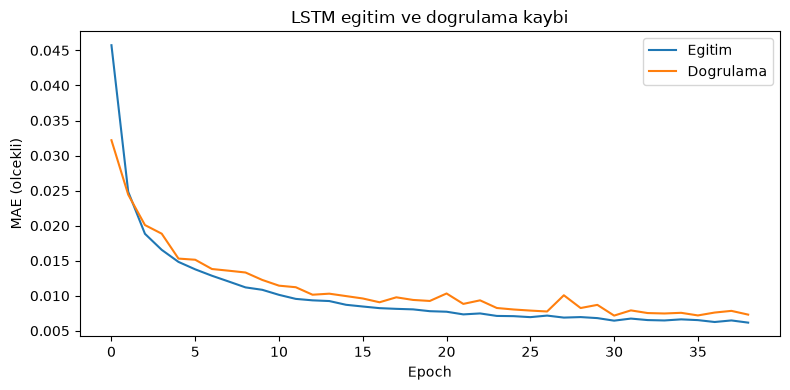

In [23]:
EGIT_LSTM = True
EPOCH = 40

if EGIT_LSTM:
    import tensorflow as tf
    from numpy.lib.stride_tricks import sliding_window_view
    from sklearn.preprocessing import MinMaxScaler
    tf.keras.utils.set_random_seed(42)

    X_all = df[F_LSTM].values.astype("float32")
    y_all = df["consumption"].values.astype("float32")
    egitim_maske = (df["bolum"] == "egitim").values
    sx = MinMaxScaler().fit(X_all[egitim_maske])
    sy = MinMaxScaler().fit(y_all[egitim_maske].reshape(-1, 1))
    Xs = sx.transform(X_all).astype("float32")
    ys = sy.transform(y_all.reshape(-1, 1)).ravel().astype("float32")

    PENCERE = 24
    kotu = np.isnan(Xs).any(axis=1)
    cs = np.concatenate([[0], np.cumsum(kotu)])
    hedef = np.arange(PENCERE, len(df))
    gecerli = ((cs[hedef] - cs[hedef - PENCERE]) == 0) & ~np.isnan(ys[hedef])
    W = sliding_window_view(Xs, PENCERE, axis=0)           # (n-23, ozellik, 24)
    bolum_h = df["bolum"].values[hedef]

    def seq(b):
        idx = hedef[gecerli & (bolum_h == b)]
        return W[idx - PENCERE].transpose(0, 2, 1).copy(), ys[idx], idx

    Xtr, ytr, _ = seq("egitim")
    Xva, yva, _ = seq("dogrulama")
    Xte, yte, ite = seq("test")
    print("Pencere sayisi | egitim:", len(Xtr), "dogrulama:", len(Xva), "test:", len(Xte))

    lstm = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(PENCERE, len(F_LSTM))),
        tf.keras.layers.LSTM(64, return_sequences=True),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1),
    ])
    lstm.compile(optimizer="adam", loss="mae")
    t0 = time.time()
    gecmis = lstm.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCH, batch_size=256, verbose=2,
                      callbacks=[tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
    print(f"LSTM egitim suresi: {(time.time() - t0) / 60:.1f} dk | epoch: {len(gecmis.history['loss'])}")

    p_te = sy.inverse_transform(lstm.predict(Xte, verbose=0)).ravel()
    lstm_seri = pd.Series(p_te, index=pd.DatetimeIndex(df["date"].iloc[ite]))
    tahmin["LSTM 1 saat ileri"] = lstm_seri.reindex(pd.DatetimeIndex(tst["date"])).values
    ok = ~np.isnan(tahmin["LSTM 1 saat ileri"].values)
    print("Ortak test kumesinde LSTM tahmini olan saat:", int(ok.sum()), "/", len(tst))
    sonuc["LSTM 1 saat ileri"] = metrik(tst["consumption"].values[ok], tahmin["LSTM 1 saat ileri"].values[ok])
    print("Test:", {k: round(v, 4) for k, v in sonuc["LSTM 1 saat ileri"].items()})

    lstm.save(os.path.join(KOK, "agent", "tr_lstm_1saat.keras"))
    joblib.dump({"sx": sx, "sy": sy, "ozellikler": F_LSTM, "pencere": PENCERE},
                os.path.join(KOK, "agent", "tr_lstm_olcekleyiciler.pkl"))

    plt.figure(figsize=(8, 4))
    plt.plot(gecmis.history["loss"], label="Egitim")
    plt.plot(gecmis.history["val_loss"], label="Dogrulama")
    plt.xlabel("Epoch"); plt.ylabel("MAE (olcekli)"); plt.title("LSTM egitim ve dogrulama kaybi"); plt.legend()
    plt.tight_layout(); plt.savefig(os.path.join(KOK, "graphs", "tr_lstm_kayip.png"), dpi=150); plt.show()
else:
    print("LSTM atlandi (EGIT_LSTM = False).")

## H. Karşılaştırma, Hata Analizi ve Kayıt

### H1. Sonuç tablosu (ortak test kümesi)

In [24]:
tablo = pd.DataFrame(sonuc).T
tablo["gorev"] = ["1 saat ileri" if ("1 saat" in i or "onceki saat" in i) else "gun oncesi / referans" for i in tablo.index]
print(tablo.sort_values(["gorev", "RMSPE"]).round(4).to_string())

tablo.round(5).to_csv(os.path.join(KOK, "metrics", "tr_model_sonuclari.csv"))
with open(os.path.join(KOK, "metrics", "tr_model_sonuclari.json"), "w", encoding="utf-8") as f:
    json.dump({"test_donemi": [str(tst["date"].min()), str(tst["date"].max())], "test_saat": int(len(tst)),
               "hdd_tabani_egitim_c": BH_TR, "cdd_tabani_egitim_c": BC_TR,
               "sonuclar": {k: {m: round(v, 5) for m, v in d.items()} for k, d in sonuc.items()}},
              f, ensure_ascii=False, indent=2)

                                            RMSPE  MAPE_%    MAE_MWh                  gorev
LSTM 1 saat ileri                          0.0107  0.7880   317.1993           1 saat ileri
XGBoost 1 saat ileri                       0.0133  0.9602   400.7885           1 saat ileri
Naif: bir onceki saat                      0.0421  3.2172  1292.8418           1 saat ileri
Resmi Yuk Tahmin Plani                     0.0359  2.5982  1043.5237  gun oncesi / referans
XGBoost gun oncesi (dunun sicakligi)       0.0376  2.8496  1189.3702  gun oncesi / referans
XGBoost gun oncesi (gerceklesen sicaklik)  0.0376  2.8666  1199.2550  gun oncesi / referans
Naif: gecen hafta ayni saat                0.0855  4.9654  1937.7696  gun oncesi / referans


### H2. Hata analizi: gün tipine ve saate göre

Gün tipleri:
- **Bayram:** Arife dahil.
- **Sabit tatil:** Bayram dışındaki tam gün tatiller.
- **İdari izin**, **hafta sonu** ve **normal iş günü**.

In [25]:
tip = np.select(
    [(tst["bayram_once_gun"] == 0) & (tst["bayram_sonra_gun"] == 0), tst["tatil_tam"] == 1, tst["idari_izin"] == 1,
     tst["hafta_sonu"] == 1],
    ["bayram (arife dahil)", "sabit tatil", "idari izin", "hafta sonu"], default="normal is gunu")
tahmin["gun_tipi"] = tip
modeller = list(sonuc.keys())

for c in modeller:
    tahmin[f"ape_{c}"] = (tahmin["gercek"] - tahmin[c]).abs() / tahmin["gercek"] * 100
tip_tablo = tahmin.groupby("gun_tipi")[[f"ape_{c}" for c in modeller]].mean()
tip_tablo.columns = modeller
tip_tablo.insert(0, "saat_sayisi", tahmin["gun_tipi"].value_counts())
print("Gun tipine gore MAPE (%):"); print(tip_tablo.round(2).to_string())

tahmin["saat"] = tahmin["date"].dt.hour
saat_tablo = tahmin.groupby("saat")[[f"ape_{c}" for c in secili]].mean()
saat_tablo.columns = secili
print("\nSaate gore MAPE (%):"); print(saat_tablo.round(2).to_string())

Gun tipine gore MAPE (%):
                      saat_sayisi  Naif: bir onceki saat  Naif: gecen hafta ayni saat  Resmi Yuk Tahmin Plani  XGBoost 1 saat ileri  XGBoost gun oncesi (gerceklesen sicaklik)  XGBoost gun oncesi (dunun sicakligi)  LSTM 1 saat ileri
gun_tipi                                                                                                                                                                                                                               
bayram (arife dahil)          216                   3.15                        33.34                    5.31                  1.25                                       4.16                                  4.11               1.35
hafta sonu                   2352                   2.96                         4.14                    2.69                  0.83                                       2.77                                  2.78               0.80
idari izin                     24             

### H3. Örnek haftalar: yaz zirvesi ve Kurban Bayramı 2026

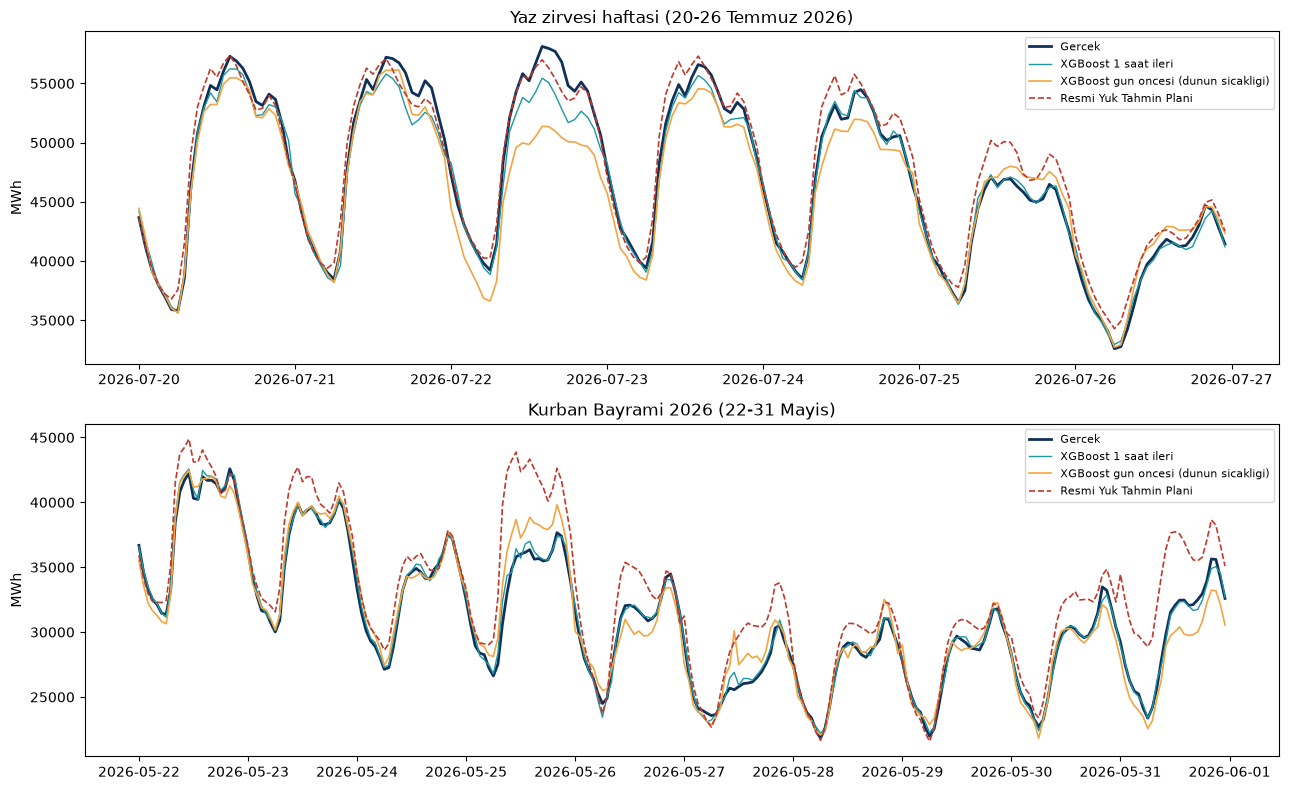

In [26]:
def ciz(ax, bas, bit, baslik):
    p = tahmin[(tahmin["date"] >= pd.Timestamp(bas)) & (tahmin["date"] < pd.Timestamp(bit))]
    ax.plot(p["date"], p["gercek"], color="#0F3057", linewidth=2, label="Gercek")
    ax.plot(p["date"], p["XGBoost 1 saat ileri"], color="#1B98A4", linewidth=1, label="XGBoost 1 saat ileri")
    ax.plot(p["date"], p["XGBoost gun oncesi (dunun sicakligi)"], color="#F2A541", linewidth=1.2,
            label="XGBoost gun oncesi (dunun sicakligi)")
    ax.plot(p["date"], p["Resmi Yuk Tahmin Plani"], color="#C0392B", linewidth=1.2, linestyle="--",
            label="Resmi Yuk Tahmin Plani")
    ax.set_title(baslik); ax.set_ylabel("MWh"); ax.legend(fontsize=8)

fig, axes = plt.subplots(2, 1, figsize=(13, 8))
ciz(axes[0], "2026-07-20T00:00:00+03:00", "2026-07-27T00:00:00+03:00", "Yaz zirvesi haftasi (20-26 Temmuz 2026)")
ciz(axes[1], "2026-05-22T00:00:00+03:00", "2026-06-01T00:00:00+03:00", "Kurban Bayrami 2026 (22-31 Mayis)")
plt.tight_layout()
plt.savefig(os.path.join(KOK, "graphs", "tr_test_ornek_haftalar.png"), dpi=150)
plt.show()

### H4. Test tahminlerinin kaydı

Agent katmanı (Faz 3) ve sunum için. Her satır bir saat: gerçek değer, bütün modellerin tahminleri, resmî plan ve gün tipi.

In [27]:
tahmin[["date", "gercek", "gun_tipi"] + modeller].to_csv(os.path.join(KOK, "metrics", "tr_test_tahminleri.csv"), index=False)
print("Kaydedildi:", len(tahmin), "satir,", len(["date", "gercek", "gun_tipi"] + modeller), "sutun")
print("Model dosyalari:", sorted(f for f in os.listdir(os.path.join(KOK, "agent")) if f.startswith("tr_")))

Kaydedildi: 8544 satir, 10 sutun
Model dosyalari: ['tr_lstm_1saat.keras', 'tr_lstm_olcekleyiciler.pkl', 'tr_xgb_1saat.json', 'tr_xgb_gunoncesi.json', 'tr_xgb_gunoncesi_dun.json']


# Beş bulgu

1. 1 saat ileri tahminde LSTM kazandı. Hata %0,79; naif tahminin dörtte birinden az. PJM projesinde tersine XGBoost kazanmıştı. Bu projede LSTM'de değişen üç şey var: ölçekleyiciler yalnızca eğitim verisiyle fit edildi, hedef için ayrı bir ölçekleyici kullanıldı, ve bayram özellikleri eklendi. Farkın hangisinden geldiğini ayrıca test etmedik.

2. Gün öncesi tahminde resmî plan bizden iyi, ama fark gün tipine göre ters dönüyor:

Gün tipi (MAPE)	Resmî plan	XGBoost gün öncesi
Normal iş günü	%2,38	%2,77
Hafta sonu	%2,69	%2,78
Sabit tatil	%3,82	%4,38
Bayram (arife dahil)	%5,31	%4,11
İdari izin	%13,91	%5,27

İdari izin satırı test dönemindeki tek bir güne dayanıyor (25 Mayıs 2026). Grafikte o gün resmî plan yaklaşık 42-44 bin MWh öngörmüş, gerçekleşen ~36 bin. Bizim model ~38-39 bin ile çok daha yakın. Tek gün olduğu için genelleme yapmak için yeterli değil.

3. Sıcaklık özelliğimiz zayıf; asıl sorun bu. Gün öncesi modelde gerçekleşen sıcaklığı kullanmak, dünün sıcaklığını kullanmaktan hiç daha iyi değil (%2,87'ye karşı %2,85). Ankara'nın gerçek sıcaklığını kusursuz bilmek bile tahmine bir şey katmıyor. Bunu destekleyen iki kanıt var:

Saate göre hata: Hatamız 14:00-17:00'de en yüksek (%3,5-3,8); resmî planın aynı saatlerde %3,0-3,2. Bunlar soğutma yükünün en yüksek olduğu saatler.
Grafik: 22 Temmuz 2026 sıcak gününde gün öncesi modelimiz zirveyi ~51 bin MWh tahmin etmiş, gerçek ~58 bin. Resmî plan zirveyi yakalamış.

Tek istasyonun günlük ortalaması, ulusal bir tüketimi açıklamaya yetmiyor.

4. Resmî plan sabah rampasında zorlanıyor. Planın en yüksek hatası 07:00-08:00'de (%3,6-3,7). Bizim modelin bu saatlerdeki hatası %2,5-2,7. Birleştirildiğinde birbirini tamamlayabilecek iki model.

5. Bayram etkisi büyük. Geçen haftanın aynı saatini tekrarlayan naif tahmin, bayramlarda %33 hata yapıyor. Tatil özelliklerimiz bunu %4'e indiriyor.